# Lift test, round 2: can the decomposition follow post-training?

Results in `experiments/lift_test/results/`, figures in `experiments/lift_test/figures/` (run `uv run python experiments/lift_test/plot.py` if missing). Scoring and every number: `reports/2026-10-14_analysis_lift-test.md`. Plan: `reports/2026-10-14_plan_lift-test.md`; amended predictions: `reports/2026-10-14_prediction_lift-test-amendment.md`.

## The question and the answer in one line

**Question (`GOALS.md`, weak version).** Given the VPD decomposition of the 67M Pile model and a small fine-tune, is there a simple map that updates the subcomponents so that the decomposition stays faithful to the fine-tuned model, with the leftover Δ not allowed to soak up the update?

**Answer on this task.** Yes, if post-training happens **inside** the decomposition: train the alive subcomponents' U and V directly (the *pull-back*). No, if post-training happens **outside** it: fine-tune W normally, then translate the finished update onto the subcomponents (the *lift*). The translated decomposition breaks under adversarial masks within a few steps.

**Terms.**
- *Alive subcomponents*: the 9 881 rank-1 subcomponents (of 38 912) with mean causal importance above 1e-6 on Pile. Only these may change.
- *Faithfulness ratio*: a VPD faithfulness KL (stochastic masks, or adversarial PGD masks) for the updated decomposition on the fine-tuned model, divided by the same KL for the released decomposition on the original model W₀. 1.0 means "as faithful as before"; the pass threshold was 1.5.
- *Obstruction*: the part of an update that no first-order change to the alive U, V can express (it reads from inputs outside every alive read vector and writes outside every alive write vector).
- Task: the paper's emoticon → `o` behaviour (arm A), 365 windows; P(o) is measured on held-out windows.

In [1]:
import json
from pathlib import Path
from IPython.display import Image, display
R = Path('../experiments/lift_test/results'); F = Path('../experiments/lift_test/figures')
load = lambda n: json.loads((R / n).read_text())
lf, pb2, pb1, proj, w = load('lift_faith.json'), load('pullback2.json'), load('pullback.json'), load('projected.json'), load('weighted.json')

## Could it do it? Inside versus outside the decomposition

Three ways of getting the emoticon behaviour, each scored by faithfulness of the decomposition afterwards:
- **outside, lift** (orange): fine-tune W, then move the expressible part of the update onto the alive subcomponents;
- **outside, do nothing** (grey dashed): fine-tune W and leave the subcomponents as they were, so Δ absorbs the update (the trivial map the weak version rules out; shown for reference);
- **inside, pull-back** (blue): train the alive U, V on the same loss, with Δ fixed.

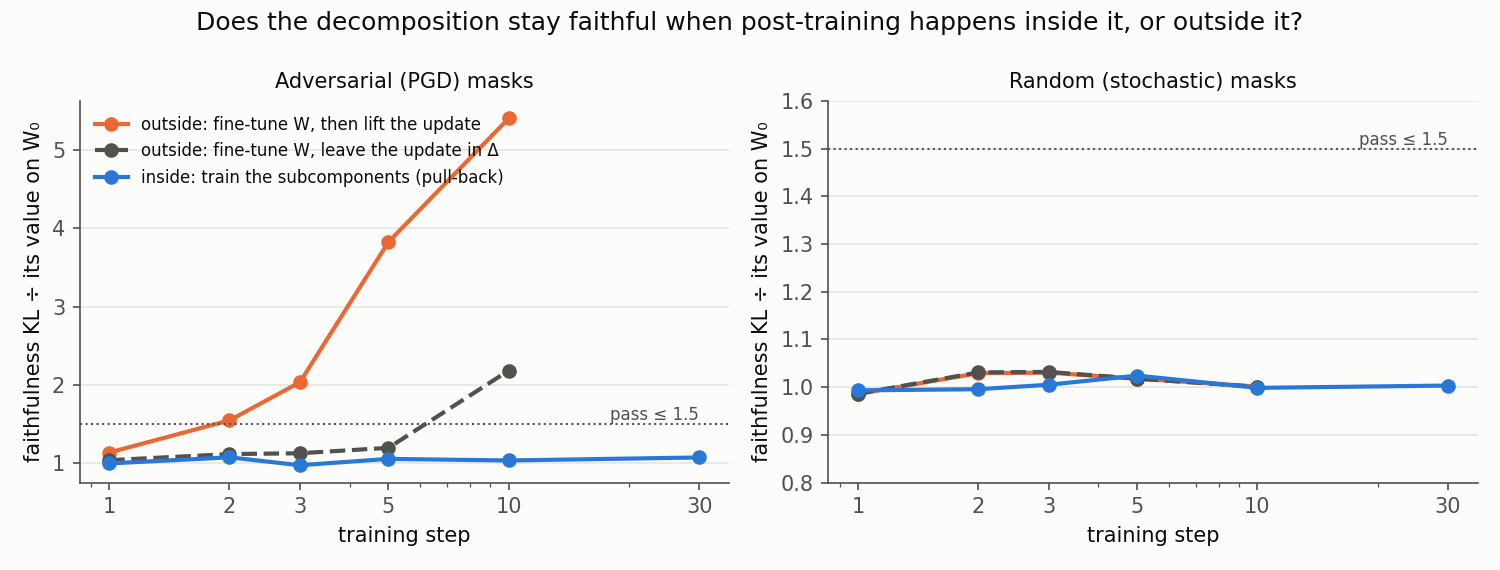

In [2]:
display(Image(F / 'inside_vs_outside.png'))

- **Inside stays faithful.** The pull-back's adversarial ratio stays between 0.97 and 1.07 at every step from 1 to 30; stochastic between 0.99 and 1.02. Δ stays at its original value to 1e-6.
- **Outside, lifted, breaks adversarially.** Random masks do not see it (ratio ≈ 1.0 throughout), but adversarial masks do: 1.14, 1.55, 2.03, 3.83, 5.41 at steps 1–10. An adversary can find masks that strip the lifted update out.
- **The lift does carry the update.** Run unmasked without Δ, the lifted subcomponents recover 88–93% of the gap the do-nothing map leaves (table below). So the failure is fragility, not absence.
- **Caveat.** The pull-back's steps 1–5 were measured afterwards on a rerun of the same run (step 10 reproduces to 0.004; `pullback2_early.json`), so they are reported, not scored. The do-nothing map is not a valid answer (Δ carries the update), but it shows the fine-tuned model itself already raises the adversarial KL to 2.2 by step 10.

In [3]:
print('step  PGD lift  PGD nothing  stoch lift  gap recovered (unmasked, no Δ)')
for s in sorted(lf['checkpoints'], key=int):
    c = lf['checkpoints'][s]; r = c['ratios']
    print(f"{s:>4}  {r['pgd_kl']['lift']:8.2f}  {r['pgd_kl']['do_nothing']:11.2f}  {r['stochastic_kl']['lift']:10.2f}  {c['gap_recovered']:.2f}")
print('pull-back ratios:', {k: {m: round(x, 3) for m, x in v.items()} for k, v in pb2['ratios'].items()})

step  PGD lift  PGD nothing  stoch lift  gap recovered (unmasked, no Δ)
   1      1.14         1.04        0.99  0.93
   2      1.55         1.12        1.03  0.88
   3      2.03         1.13        1.03  0.88
   5      3.83         1.20        1.02  0.89
  10      5.41         2.18        1.00  0.89
pull-back ratios: {'pullback_step10': {'ci_masked_kl': 1.002, 'pgd_kl': 1.034, 'stochastic_kl': 0.999, 'unmasked_kl': 1.006}, 'pullback_step30': {'ci_masked_kl': 1.004, 'pgd_kl': 1.073, 'stochastic_kl': 1.003, 'unmasked_kl': 0.999}}


## Does it match the prediction? Scorecard

Predictions were filed before each run. P2 and P3 were superseded by an amendment (P2′, P3′) after their first versions turned out not to be testable as written; the original file is unchanged.

In [4]:
rows = [
 ('P1  update mostly expressible (ω ≤ 0.1)', 'pass', 'REVERSED: ω = 0.54 vs noise 0.59 (parameter space)'),
 ('P2  lift faithful incl. weight term', 'pass', 'unscorable: weight term blind (do-nothing ratio 1.004)'),
 ('P3  pull-back, filed lr grid', 'pass', f"FAILED as filed: PGD ratio {pb1['ratios']['pullback']['pgd_kl']:.0f} (lr {pb1['best_lr']:g}, steps 3–100× too large)"),
 ('P2′ lift faithful (PGD ≤ 1.5, gap ≥ 0.5)', 'pass', f"REVERSED: passes at step 1 only; PGD {lf['checkpoints']['10']['ratios']['pgd_kl']['lift']:.2f} at step 10"),
 ('P3′ pull-back, matched step size', 'pass', f"PASSED: P(o) {pb2['runs']['1e-05']['curve'][9]['heldout_p_o']:.3f}, PGD {pb2['ratios']['pullback_step10']['pgd_kl']:.2f} at step 10"),
]
for r in rows: print(f'{r[0]:<45} predicted {r[1]:<5} | {r[2]}')

P1  update mostly expressible (ω ≤ 0.1)       predicted pass  | REVERSED: ω = 0.54 vs noise 0.59 (parameter space)
P2  lift faithful incl. weight term           predicted pass  | unscorable: weight term blind (do-nothing ratio 1.004)
P3  pull-back, filed lr grid                  predicted pass  | FAILED as filed: PGD ratio 41 (lr 0.0003, steps 3–100× too large)
P2′ lift faithful (PGD ≤ 1.5, gap ≥ 0.5)      predicted pass  | REVERSED: passes at step 1 only; PGD 5.41 at step 10
P3′ pull-back, matched step size              predicted pass  | PASSED: P(o) 1.000, PGD 1.03 at step 10


## Does the inside route cost anything in behaviour?

Held-out P(o) and the off-target damage (KL to the original model at the other 40 positions of each window) for the pull-back at lr 1e-5 and for the normal W fine-tune with Adam.

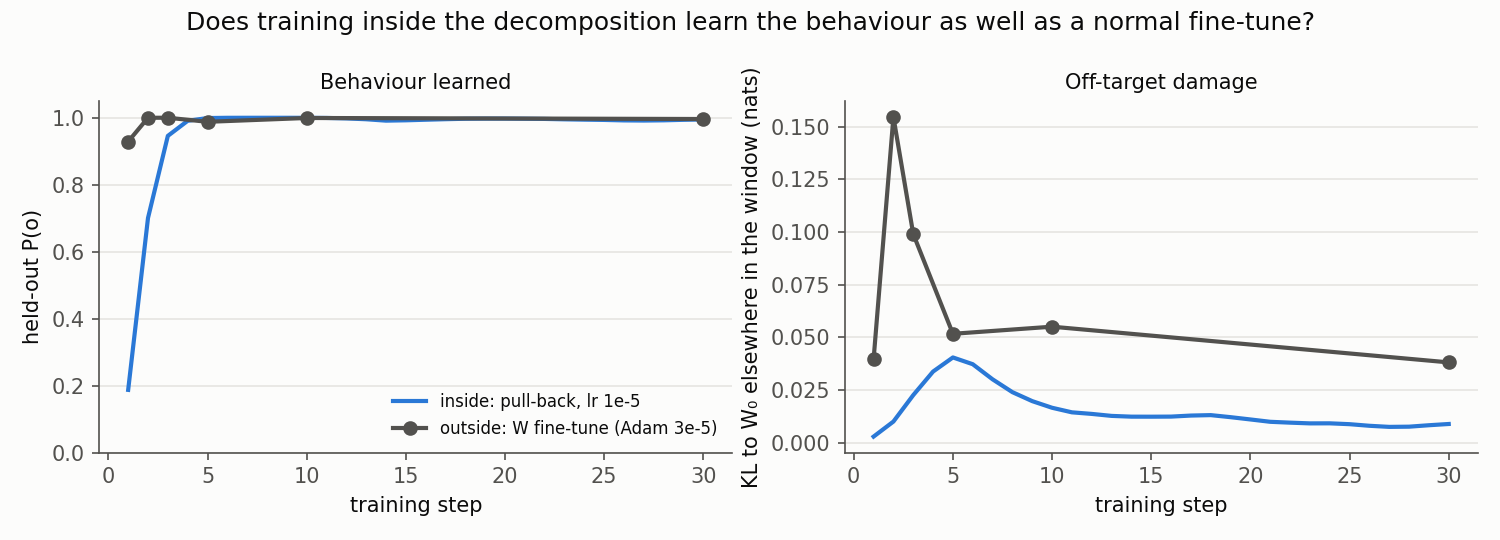

In [5]:
display(Image(F / 'pullback_behaviour.png'))

- **Behaviour.** The pull-back is slower at the start (P(o) 0.19 at step 1, 0.95 at step 3) but matches the W fine-tune from step 4 on.
- **Off-target.** It does about a third of the damage: 0.017 nats at step 10 against 0.055.
- **Size.** Its largest relative weight change is about half the fine-tune's (0.005 against 0.011 at step 10).
- So restricting post-training to the decomposition costs a couple of steps and nothing else here.

## Why does the outside route fail? How much of an update can the subcomponents express at all?

The share of each update that no first-order change to the alive subcomponents can express, in parameter space (grey) and weighted by the inputs each matrix actually sees on Pile (blue), against the same for a random update (light). The original weights W₀ are included as a reference. Pooled over the 20 matrices where the share can be non-zero.

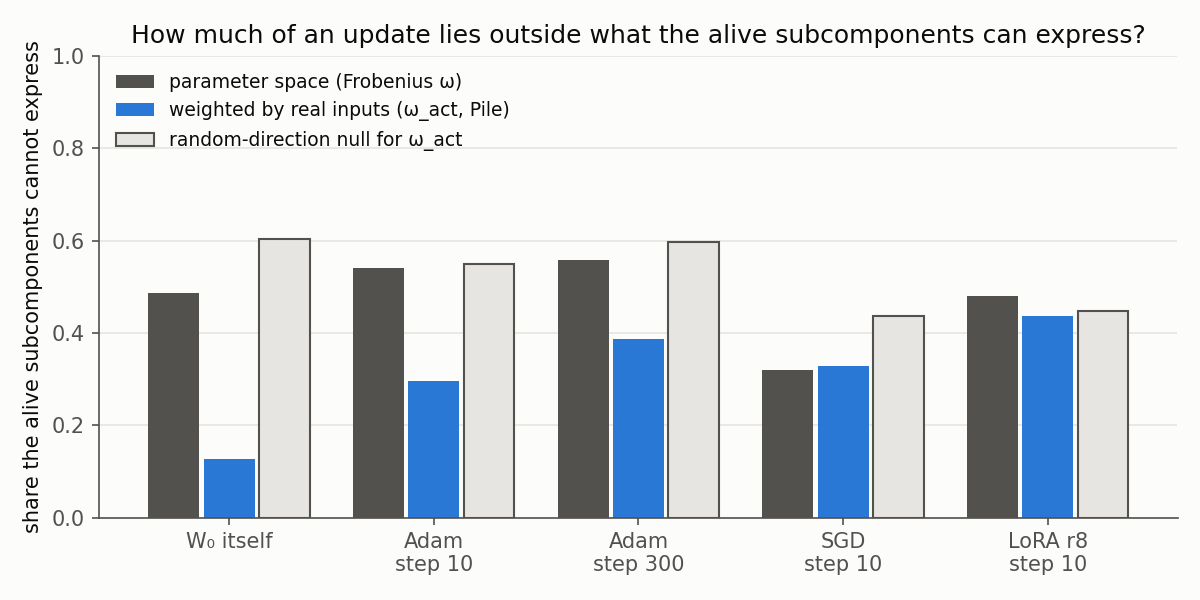

In [6]:
display(Image(F / 'obstruction.png'))

- **Parameter space is the wrong yardstick.** W₀ itself is only half expressible by that measure (0.49), the same as the updates.
- **Weighted by real inputs**, the alive subcomponents carry W₀ well (0.13 left over against 0.60 for noise). A normal fine-tune leaves about 0.30 at step 10, rising to 0.39 by step 300: better than noise, worse than the weights.
- **Not the optimiser.** SGD and Adam leave about the same input-weighted share.
- **LoRA ≈ noise**, an artefact: its read matrix is still close to its random initialisation.

## Does the inexpressible part matter for the behaviour?

Each fine-tune split in two: the expressible part only, and the inexpressible part only, evaluated against the full update.

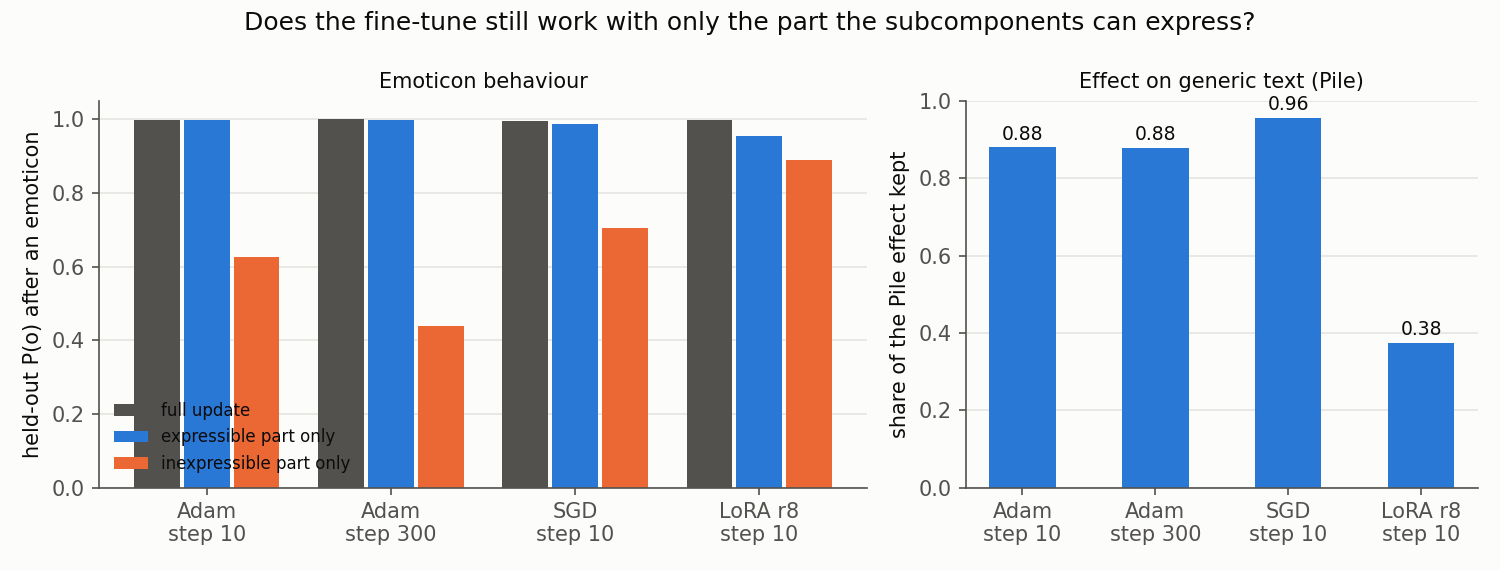

In [7]:
display(Image(F / 'projected.png'))

- **No.** The expressible part alone keeps the emoticon behaviour entirely and 85–96% of the full fine-tunes' effect on Pile text (LoRA: 38% of a very small effect).
- **The behaviour is redundant.** The inexpressible part alone also gives P(o) 0.4–0.9.
- Together with the first figure: what the optimiser puts outside the decomposition is not needed, but once the rest is moved onto the subcomponents it is adversarially fragile. Training inside avoids both problems. That is consistent with fine-tuning having many solutions, of which the optimiser picks one that fits the decomposition poorly. It is a reading, not a tested cause.

## What this does not show

- **One task, and the easiest.** The paper already found a subcomponent for the emoticon behaviour, so it is not a new capability. A behaviour the model lacks is the real test of the "new capabilities" branch of the question.
- **Short.** 30 steps of a 4-layer model; Γ frozen throughout. Where the inside route stops working is unknown.
- **Faithful is not interpretable.** Whether the subcomponents the pull-back changed still read and write what they did is not measured.
- **Cause of the lift's fragility** not established; one candidate is that the lift ignores which subcomponents Γ marks as important on the inputs where the update acts (theory note, locality residual ρ).